In [3]:

from typing import List, TypedDict
import time

from langchain_classic.document_loaders import PyPDFLoader
from langchain_chroma import Chroma
from langchain_ollama import OllamaEmbeddings, ChatOllama
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate


from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

load_dotenv()

True

In [13]:
docs = PyPDFLoader('../documents/MilanRaiMERN.pdf').load()

In [14]:
len(docs)

1

In [15]:
chunks = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150).split_documents(docs)

# 3) Clean text to avoid UnicodeEncodeError (surrogates from PDF extraction)
for d in chunks:
    d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")

In [16]:
embeddings = OllamaEmbeddings(
    model="nomic-embed-text",
)

vector_store = Chroma.from_documents(documents=chunks, embedding=embeddings, persist_directory="./chromadb")

In [18]:
retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k':4})


In [19]:
llm = ChatOllama(model='llama3.2', temperature=0)


In [20]:
class State(TypedDict): 
    question: str
    docs : List[Document]
    answer: str


In [21]:
def retrieve(state: State): 
    q = state['question']
    return {"docs": retrieve.invoke(q)}

In [22]:
prompt = ChatPromptTemplate.from_messages(
    [
        ("system", "Answer only from the context. If not in context, say you don't know."),
        ("human", "Question: {question}\n\nContext:\n{context}"),
    ]
)
def generate(state):
    context = "\n\n".join(d.page_content for d in state["docs"])
    out = (prompt | llm).invoke({"question": state["question"], "context": context})
    return {"answer": out.content}

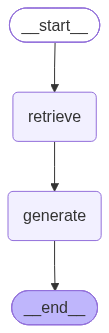

In [23]:

g = StateGraph(State)
g.add_node("retrieve", retrieve)
g.add_node("generate", generate)
g.add_edge(START, "retrieve")
g.add_edge("retrieve", "generate")
g.add_edge("generate", END)
app = g.compile()

app

In [24]:
res = app.invoke({"question": "WHat is a transformer in deep learning.", "docs": [], "answer": ""})
print(res["answer"])


AttributeError: 'function' object has no attribute 'invoke'